# Data Exploration — SROIE (ICDAR 2019)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chundawat-h/Receipt-Invoice-Information-Extraction/blob/main/notebooks/01_data_exploration.ipynb)

**Issue #4** (Hiranya). We look at the data before training anything, because the BERT (#5) and LayoutLM (#6) notebooks, the evaluation (#2) and the report all depend on it.

### Two Hugging Face versions of SROIE, used together

| Version | What we use it for |
|---|---|
| [`darentang/sroie`](https://huggingface.co/datasets/darentang/sroie) | **Training data.** One BIO tag per word (`B-COMPANY`, …) and boxes already scaled to 0–1000. This is exactly what BERT/LayoutLM token classification needs. |
| [`jsdnrs/ICDAR2019-SROIE`](https://huggingface.co/datasets/jsdnrs/ICDAR2019-SROIE) | **Receipt images** and the **official ICDAR answers** (`entities`: company/date/address/total). It has no per-word tags. |

Both versions contain the same receipt scans. They are joined on the receipt **key**, which is the image file name without `.jpg` (e.g. `X00016469612`).

What this notebook checks:
1. Both datasets load and every receipt can be matched between them
2. Columns, one example, the label names
3. Whether `bboxes` are in the 0–1000 range LayoutLM needs
4. Statistics: receipts, words per receipt, label distribution
5. Receipt length in **BERT sub-tokens** (anything over 512?)
6. What the tagged field spans look like, and how they compare with the official answers
7. Receipt images with word boxes coloured by label (figures for the report)

Figures are saved to `results/`. A summary of the findings is at the end.

In [1]:
!pip install -q transformers "datasets<3" seqeval

In [2]:
import collections
import difflib
import re
import string
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from matplotlib.patches import Patch, Rectangle

# Works both from the repo (notebooks/ -> ../results) and in a fresh Colab runtime (./results)
ROOT = Path("..") if Path("../results").is_dir() else Path(".")
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

FIELDS = ["company", "date", "address", "total"]
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 110

## 1. Load both datasets

**`darentang/sroie`**: we load the Hugging Face auto-converted **Parquet** copy (`revision="refs/convert/parquet"`). Loading it the plain way runs a script that downloads a 456 MB zip from Google Drive, which often fails, and needs `trust_remote_code`. The Parquet copy has the same rows, is about 1 MB and runs no code. **BERT (#5) and LayoutLM (#6) should load it the same way.**

In [3]:
ds = load_dataset("darentang/sroie", revision="refs/convert/parquet")

# The receipt key = image file name without extension. It is the same in both datasets.
ds = ds.map(lambda r: {"key": Path(r["image_path"]).stem})
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 626
    })
    test: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 347
    })
})

**`jsdnrs/ICDAR2019-SROIE`** is about 510 MB because it contains the images. To get the official answers we **stream** only the `key`, `entities` and `image_size` columns, so nothing large is downloaded or stored. Images are streamed later, only for the receipts we draw.

In [4]:
OFFICIAL = "jsdnrs/ICDAR2019-SROIE"

official = {
    split: {r["key"]: r for r in load_dataset(OFFICIAL, split=split, streaming=True,
                                               columns=["key", "entities", "image_size"])}
    for split in ["train", "test"]
}
{split: len(rows) for split, rows in official.items()}

{'train': 626, 'test': 361}

In [5]:
# Can every darentang receipt be matched to an official one (same split)?
join = []
for split in ds:
    ours = list(ds[split]["key"])
    theirs = list(official[split])
    join.append({
        "split": split,
        "darentang receipts": len(ours),
        "jsdnrs receipts": len(theirs),
        "darentang keys missing in jsdnrs": len(set(ours) - set(theirs)),
        "extra jsdnrs keys": len(set(theirs) - set(ours)),
        "same order": ours == [k for k in theirs if k in set(ours)],
    })
pd.DataFrame(join).set_index("split")

,darentang receipts,jsdnrs receipts,darentang keys missing in jsdnrs,extra jsdnrs keys,same order
split,,,,,
train,626,626,0,0,True
test,347,361,0,14,True


Every `darentang` receipt has a matching official receipt, in the same order. `jsdnrs` has **14 extra test receipts**: these are the test answers that were missing from the original ICDAR release. They have no per-word tags, so the models can't be trained or scored on them in the same way. **All methods are evaluated on the 347 shared test receipts.**

## 2. Columns, one example, labels

In [6]:
LABELS = ds["train"].features["ner_tags"].feature.names
id2label = dict(enumerate(LABELS))
label2id = {label: i for i, label in id2label.items()}

print("columns :", ds["train"].column_names)
print("labels  :", LABELS)
print("id2label:", id2label)

columns : ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key']
labels  : ['O', 'B-COMPANY', 'I-COMPANY', 'B-DATE', 'I-DATE', 'B-ADDRESS', 'I-ADDRESS', 'B-TOTAL', 'I-TOTAL']
id2label: {0: 'O', 1: 'B-COMPANY', 2: 'I-COMPANY', 3: 'B-DATE', 4: 'I-DATE', 5: 'B-ADDRESS', 6: 'I-ADDRESS', 7: 'B-TOTAL', 8: 'I-TOTAL'}


In [7]:
ex = ds["train"][0]
print("key:", ex["key"], "| words:", len(ex["words"]))
print("official answers:", official["train"][ex["key"]]["entities"])
pd.DataFrame({
    "word": ex["words"],
    "bbox": ex["bboxes"],
    "label": [LABELS[t] for t in ex["ner_tags"]],
}).head(40)

key: X00016469612 | words: 89
official answers: {'company': 'BOOK TA .K (TAMAN DAYA) SDN BHD', 'date': '25/12/2018', 'address': 'NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.', 'total': '9.00'}


,word,bbox,label
0,tan,"[157, 29, 280, 58]",O
1,woon,"[293, 30, 503, 60]",O
2,yann,"[518, 32, 697, 61]",O
3,BOOK,"[151, 92, 276, 111]",B-COMPANY
4,TA,"[282, 91, 332, 111]",I-COMPANY
5,_K,"[339, 91, 384, 111]",I-COMPANY
6,(TAMAN,"[390, 90, 565, 111]",I-COMPANY
7,DAYA),"[572, 90, 708, 111]",I-COMPANY
8,SDN,"[714, 90, 807, 110]",I-COMPANY
9,BHD,"[814, 91, 909, 110]",I-COMPANY


In [8]:
# Sanity check: words, boxes and tags line up in every receipt
for split in ds:
    bad = [r["key"] for r in ds[split] if not (len(r["words"]) == len(r["bboxes"]) == len(r["ner_tags"]))]
    print(f"{split}: {len(bad)} receipts with mismatched lengths")

train: 0 receipts with mismatched lengths
test: 0 receipts with mismatched lengths


## 3. Bounding boxes — are they already 0–1000?

LayoutLM expects every box as `[x0, y0, x1, y1]` scaled to 0–1000 relative to the page width and height.

In [9]:
def bbox_report(split):
    b = np.concatenate([np.asarray(x) for x in ds[split]["bboxes"]])
    return {
        "split": split,
        "boxes": len(b),
        "x min": b[:, [0, 2]].min(), "x max": b[:, [0, 2]].max(),
        "y min": b[:, [1, 3]].min(), "y max": b[:, [1, 3]].max(),
        "outside 0-1000": int(((b < 0) | (b > 1000)).any(axis=1).sum()),
        "x0 > x1": int((b[:, 0] > b[:, 2]).sum()),
        "y0 > y1": int((b[:, 1] > b[:, 3]).sum()),
    }

pd.DataFrame([bbox_report(s) for s in ds]).set_index("split")

,boxes,x min,x max,y min,y max,outside 0-1000,x0 > x1,y0 > y1
split,,,,,,,,
train,73747,0,998,0,999,0,0,0
test,40411,0,998,0,999,0,0,0


## 4. Statistics

In [10]:
n_words = {s: pd.Series([len(w) for w in ds[s]["words"]]) for s in ds}
stats = pd.DataFrame({s: v.describe() for s, v in n_words.items()}).T
stats = stats.rename(columns={"count": "receipts"}).astype({"receipts": int})
stats.round(1)

,receipts,mean,std,min,25%,50%,75%,max
train,626,117.8,31.6,31.0,94.2,112.5,136.0,246.0
test,347,116.5,32.1,61.0,93.0,109.0,132.0,231.0


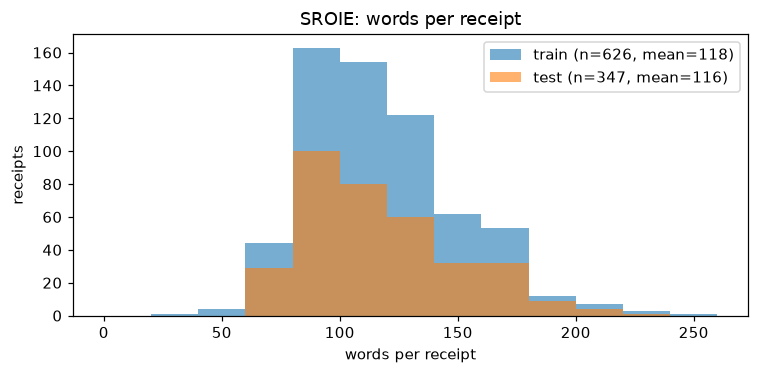

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, max(v.max() for v in n_words.values()) + 20, 20)
for s, v in n_words.items():
    ax.hist(v, bins=bins, alpha=0.6, label=f"{s} (n={len(v)}, mean={v.mean():.0f})")
ax.set_xlabel("words per receipt")
ax.set_ylabel("receipts")
ax.set_title("SROIE: words per receipt")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "words_per_receipt.png", dpi=150)
plt.show()

### Label distribution (word level)

In [12]:
label_counts = pd.DataFrame({
    s: pd.Series(collections.Counter(LABELS[t] for tags in ds[s]["ner_tags"] for t in tags))
    for s in ds
}).reindex(LABELS).fillna(0).astype(int)
for s in ds:
    label_counts[f"{s} %"] = (100 * label_counts[s] / label_counts[s].sum()).round(2)
label_counts

,train,test,train %,test %
O,62469,34216,84.71,84.67
B-COMPANY,626,347,0.85,0.86
I-COMPANY,2095,1144,2.84,2.83
B-DATE,626,347,0.85,0.86
I-DATE,112,81,0.15,0.20
B-ADDRESS,625,347,0.85,0.86
I-ADDRESS,6519,3560,8.84,8.81
B-TOTAL,626,347,0.85,0.86
I-TOTAL,49,22,0.07,0.05


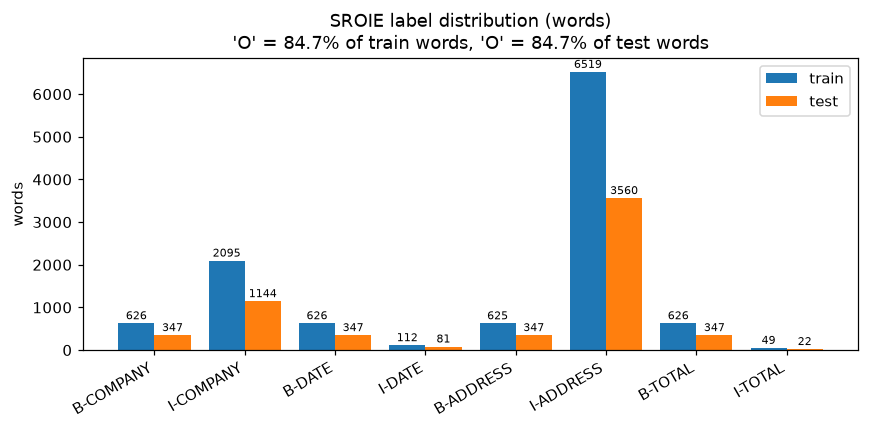

In [13]:
# 'O' dominates, so plot the field labels on a linear scale and give the 'O' share in the title
field_labels = [l for l in LABELS if l != "O"]
o_share = {s: 100 * label_counts.loc["O", s] / label_counts[s].sum() for s in ds}

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(field_labels))
width = 0.4
for i, s in enumerate(ds):
    bars = ax.bar(x + (i - 0.5) * width, label_counts.loc[field_labels, s], width, label=s)
    ax.bar_label(bars, fontsize=7, padding=1)
ax.set_xticks(x, field_labels, rotation=30, ha="right")
ax.set_ylabel("words")
ax.set_title("SROIE label distribution (words)\n"
             + ", ".join(f"'O' = {o_share[s]:.1f}% of {s} words" for s in ds))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "label_distribution.png", dpi=150)
plt.show()

In [14]:
# How many receipts contain each field at all?
def has_field(tags, field):
    return any(LABELS[t].endswith("-" + field.upper()) for t in tags)

coverage = pd.DataFrame({
    s: {f: 100 * np.mean([has_field(tags, f) for tags in ds[s]["ner_tags"]]) for f in FIELDS}
    for s in ds
}).round(1)
coverage.index.name = "% of receipts with field"
coverage

,train,test
% of receipts with field,,
company,100.0,100.0
date,100.0,100.0
address,99.8,100.0
total,100.0,100.0


## 5. Length in BERT sub-tokens

BERT and LayoutLM read at most **512 sub-tokens** (510 plus `[CLS]` and `[SEP]`). Words are split into WordPiece sub-tokens, so a receipt can be longer than its word count. Words past the limit get no prediction. This matters for #5 and #6.

In [15]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased")
tok_lm = AutoTokenizer.from_pretrained("microsoft/layoutlm-base-uncased")
print("BERT and LayoutLM use the same vocabulary:", tok.get_vocab() == tok_lm.get_vocab())

BERT and LayoutLM use the same vocabulary: True


In [16]:
MAX_LEN = 512

def length_info(row):
    n = len(tok(row["words"], is_split_into_words=True, truncation=False, verbose=False)["input_ids"])
    kept = tok(row["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN).word_ids()
    kept = {w for w in kept if w is not None}
    lost = [i for i in range(len(row["words"])) if i not in kept]
    return {"subtokens": n, "words_lost": len(lost),
            "field_words_lost": sum(row["ner_tags"][i] != 0 for i in lost)}

lengths = {s: pd.DataFrame([length_info(r) for r in ds[s]]) for s in ds}
pd.DataFrame({
    s: {
        "mean sub-tokens": df.subtokens.mean(),
        "max sub-tokens": df.subtokens.max(),
        "sub-tokens per word": df.subtokens.sum() / n_words[s].sum(),
        f"receipts > {MAX_LEN}": int((df.subtokens > MAX_LEN).sum()),
        "words lost to truncation": int(df.words_lost.sum()),
        "field words lost": int(df.field_words_lost.sum()),
    }
    for s, df in lengths.items()
}).round(2)

,train,test
mean sub-tokens,258.47,256.06
max sub-tokens,561.00,525.00
sub-tokens per word,2.19,2.20
receipts > 512,4.00,1.00
words lost to truncation,51.00,9.00
field words lost,0.00,0.00


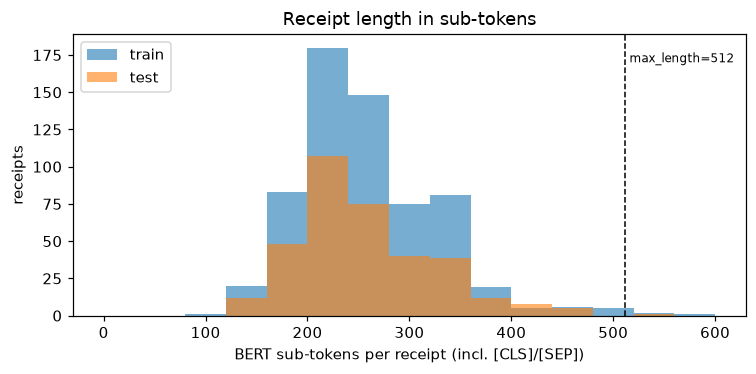

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, max(df.subtokens.max() for df in lengths.values()) + 40, 40)
for s, df in lengths.items():
    ax.hist(df.subtokens, bins=bins, alpha=0.6, label=s)
ax.axvline(MAX_LEN, color="k", ls="--", lw=1)
ax.text(MAX_LEN, ax.get_ylim()[1] * 0.9, f" max_length={MAX_LEN}", fontsize=8)
ax.set_xlabel("BERT sub-tokens per receipt (incl. [CLS]/[SEP])")
ax.set_ylabel("receipts")
ax.set_title("Receipt length in sub-tokens")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "subtokens_per_receipt.png", dpi=150)
plt.show()

## 6. Field spans: tagged words vs. official answers

A BERT/LayoutLM prediction is a set of tagged words. To turn that into a field string we join the words, which is what `bio_to_fields` in `src/evaluate.py` (#2) does. Here we do the same to the **gold tags** and look at the result.

In [18]:
def field_spans(words, tags):
    # Group words into spans per field: B- (or an I- that doesn't continue) starts a new span
    spans = {f: [] for f in FIELDS}
    cur, buf = None, []
    for word, t in zip(words, tags):
        label = LABELS[t]
        prefix, field = (label.split("-")[0], label.split("-")[1].lower()) if label != "O" else (None, None)
        if field is not None and prefix == "I" and field == cur:
            buf.append(word)
            continue
        if cur:
            spans[cur].append(" ".join(buf))
        cur, buf = (field, [word]) if field else (None, [])
    if cur:
        spans[cur].append(" ".join(buf))
    return spans

spans = {s: {r["key"]: field_spans(r["words"], r["ner_tags"]) for r in ds[s]} for s in ds}

def span_stats(split_spans):
    rows = {}
    for f in FIELDS:
        n = [len(s[f]) for s in split_spans.values() if s[f]]
        n_distinct = [len(set(s[f])) for s in split_spans.values() if s[f]]
        rows[f] = {
            "mean spans / receipt": np.mean(n),
            "% receipts with >1 span": 100 * np.mean([k > 1 for k in n]),
            "% with >1 *different* span": 100 * np.mean([k > 1 for k in n_distinct]),
            "mean words / span": np.mean([len(x.split()) for s in split_spans.values() for x in s[f]]),
        }
    return pd.DataFrame(rows).T.round(2)

span_stats(spans["test"])

,mean spans / receipt,% receipts with >1 span,% with >1 *different* span,mean words / span
company,1.0,0.0,0.0,4.30
date,1.0,0.0,0.0,1.23
address,1.0,0.0,0.0,11.26
total,1.0,0.0,0.0,1.06


### How close is "perfect tagging" to the official answer?

Suppose a model tagged **every word exactly right**. Its joined string would still differ from the official answer when the OCR misread a character, or when spacing differs (`30 ,` vs `30,`). Here we score the gold tags against the official answers using the same normalisation as `src/evaluate.py`: lowercase, collapse spaces, strip punctuation at the ends, and for `total` drop `RM` and commas. The result is the **highest score any tagging model can reach** when scored against the official answers.

In [19]:
_P = string.punctuation

def normalize(text, field=None):
    text = " ".join(str(text or "").lower().split()).strip(_P + " ")
    if field == "total":
        text = re.sub(r"^(rm|myr|\$)\s*", "", text).replace(",", "").replace(" ", "")
    return text

def ceiling(split):
    rows = {}
    for f in FIELDS:
        exact, nospace, sim = [], [], []
        for key, sp in spans[split].items():
            pred = normalize(" ".join(dict.fromkeys(sp[f])), f)
            gold = normalize(official[split][key]["entities"][f], f)
            exact.append(pred == gold)
            nospace.append(pred.replace(" ", "") == gold.replace(" ", ""))
            sim.append(difflib.SequenceMatcher(None, pred, gold).ratio())
        rows[f] = {"exact match %": 100 * np.mean(exact),
                   "exact, ignoring spaces %": 100 * np.mean(nospace),
                   "mean character similarity": np.mean(sim)}
    df = pd.DataFrame(rows).T
    df.loc["macro avg"] = df.mean()
    return df.round(3)

ceiling_test = ceiling("test")
ceiling_test.to_csv(RESULTS / "oracle_ceiling_vs_official.csv")
ceiling_test

,exact match %,"exact, ignoring spaces %",mean character similarity
company,80.403,80.692,0.987
date,96.254,96.254,0.991
address,58.213,74.352,0.990
total,96.254,96.254,0.991
macro avg,82.781,86.888,0.990


In [20]:
# Why it isn't 100%: examples where perfect tags != official answer (test split)
rows = []
for f in FIELDS:
    for key, sp in spans["test"].items():
        pred = " ".join(dict.fromkeys(sp[f]))
        gold = official["test"][key]["entities"][f]
        if normalize(pred, f) != normalize(gold, f):
            rows.append({"field": f, "key": key, "joined gold tags": pred, "official answer": gold})
mismatch = pd.DataFrame(rows)
mismatch.groupby("field").head(4).reset_index(drop=True)

,field,key,joined gold tags,official answer
0,company,X51005230621,SIN LIANHAP SON BHD,SIN LIANHAP SDN BHD
1,company,X51005337867,Old Town Kopitiam Sdn Bhd,OLD TOWN KOPITAM SND BHD
2,company,X51005361906,TEO HENG STATIONERY & BOOKS,TED HENG STATIONERY & BOOKS
3,company,X51005361908,TED HENG STATIONERY & BOOKS,TEO HENG STATIONERY & BOOKS
4,date,X51005568887,28/04/2017,26/04/2017
5,date,X51005675914,Date 10/1/2017,10/11/2017
6,date,X51005746204,236100411023 27/11/2018,27/MAR/2018
7,date,X51005806719,"13/01/201 ,",13/01/2018
8,address,X00016469670,"NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR","NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, B1750 MASAI, JOHOR"
9,address,X51005230605,"KM 458.4 BKT LANJAN UTARA, L/RAYA UTARA SELATAN, SG BULOH 47000 SUNGAI BUL","KM 458.4 BKT LANJAN UTARA, L/RAYA UTARA SELATAN,SG BULOH 47000 SUNGAI BUL"


### Do DATE spans contain only the date?

The regex baseline (#3) outputs only the date itself. If a gold span also contained `Date:` or a time, the regex would be marked wrong unfairly.

In [21]:
DATE_ONLY = re.compile(
    r"^\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}$"                    # 25/12/2018, 25-12-18, 25.12.2018
    r"|^\d{4}[/\-.]\d{1,2}[/\-.]\d{1,2}$"                     # 2018-12-25
    r"|^\d{1,2}[ \-/]?[a-z]{3}[a-z]*[ \-/,]?\d{2,4}$",        # 25 DEC 2018, 25-Dec-18, 02/Jan/2017
    re.I,
)
date_spans = [x for s in spans["test"].values() for x in s["date"]]
ok = [bool(DATE_ONLY.match(x.strip())) for x in date_spans]
print(f"test DATE spans: {len(date_spans)} | only a date: {np.mean(ok):.1%}")
print("spans that are NOT a bare date:")
for x in [x for x, good in zip(date_spans, ok) if not good][:15]:
    print("   ", repr(x))

test DATE spans: 347 | only a date: 97.4%
spans that are NOT a bare date:
    'Date 10/1/2017'
    '236100411023 27/11/2018'
    '13/01/201 ,'
    'Date:07/02/17'
    'Date:23/02/17'
    '#2 3 /04/2017'
    'Date:21/05/17'
    '12/06/2016-13:30:10-28-NORBAIZURA'
    '01/05/2016-13:19:16-29-NORBAIZURA'


### Which occurrence of the total is tagged?

A receipt usually prints the total amount several times: the item price, the subtotal, the `TOTAL` line, sometimes the cash paid. Each field has exactly one tagged span (see the table above), so `darentang` tagged only **one** of those occurrences. Below we check whether it is the one on the `TOTAL` line. A word counts as on the same line when its box overlaps the tagged word's box vertically by more than half.

For **scoring** this doesn't matter, because all occurrences are the same string. For **training** it does: if the tag is often on the wrong occurrence, the "same line as TOTAL" layout cue is weaker than expected.

In [22]:
TOTAL_WORDS = re.compile(r"total|amount|amt|jumlah|grand|nett|due|payable", re.I)

def same_line(b, c):
    overlap = min(b[3], c[3]) - max(b[1], c[1])
    return overlap > 0.5 * min(b[3] - b[1], c[3] - c[1])

def total_position(row):
    tagged = [i for i, t in enumerate(row["ner_tags"]) if LABELS[t] == "B-TOTAL"][0]
    value = normalize(row["words"][tagged], "total")
    occurrences = [i for i, w in enumerate(row["words"]) if normalize(w, "total") == value]
    line = [w for w, b in zip(row["words"], row["bboxes"]) if same_line(b, row["bboxes"][tagged])]
    return {
        "key": row["key"],
        "value printed n times": len(occurrences),
        "tagged = first occurrence": tagged == occurrences[0],
        "TOTAL keyword on tagged line": any(TOTAL_WORDS.search(w) for w in line),
    }

total_pos = pd.DataFrame([total_position(r) for r in ds["train"]])
print(f"train receipts: {len(total_pos)}")
print(f"  total value printed more than once : {(total_pos['value printed n times'] > 1).mean():.1%}")
print(f"  tagged word is the first occurrence: {total_pos['tagged = first occurrence'].mean():.1%}")
print(f"  'total'-like keyword on tagged line: {total_pos['TOTAL keyword on tagged line'].mean():.1%}")

train receipts: 626
  total value printed more than once : 70.0%
  tagged word is the first occurrence: 96.2%
  'total'-like keyword on tagged line: 66.9%


## 7. Receipts with word boxes coloured by label

The images come from `jsdnrs/ICDAR2019-SROIE` (streamed, matched by key). The `darentang` boxes are scaled back from 0–1000 to pixels (`x * width / 1000`). If they sit on the printed words, that confirms the boxes are already normalised.

In [23]:
COLORS = {"company": "#1f77b4", "date": "#2ca02c", "address": "#ff7f0e", "total": "#d62728"}

def fetch_images(split, keys):
    # Stream the official split and keep only the images we need (stops early)
    keys, found = set(keys), {}
    for r in load_dataset(OFFICIAL, split=split, streaming=True, columns=["key", "image"]):
        if r["key"] in keys:
            found[r["key"]] = r["image"].convert("RGB")
            if len(found) == len(keys):
                break
    return found

def draw_receipt(row, img, save_as=None):
    W, H = img.size
    fig, ax = plt.subplots(figsize=(6, 6 * H / W))
    ax.imshow(img)
    for (x0, y0, x1, y1), t in zip(row["bboxes"], row["ner_tags"]):
        label = LABELS[t]
        field = label.split("-")[1].lower() if label != "O" else None
        x0, x1, y0, y1 = x0 * W / 1000, x1 * W / 1000, y0 * H / 1000, y1 * H / 1000
        if field:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=COLORS[field],
                                   alpha=0.35, edgecolor=COLORS[field], linewidth=1.5))
        else:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="0.55", linewidth=0.6))
    handles = [Patch(color=c, alpha=0.6, label=f.upper()) for f, c in COLORS.items()]
    handles.append(Patch(fill=False, edgecolor="0.55", label="O (other)"))
    ax.legend(handles=handles, loc="upper right", fontsize=8, framealpha=0.9)
    ax.set_title(f"SROIE receipt {row['key']}", fontsize=9)
    ax.axis("off")
    fig.tight_layout()
    if save_as:
        fig.savefig(RESULTS / save_as, dpi=150, bbox_inches="tight")
    plt.show()

FIGURE_ROWS = [ds["train"][0], ds["train"][5]]
images = fetch_images("train", [r["key"] for r in FIGURE_ROWS])
for row in FIGURE_ROWS:
    size = official["train"][row["key"]]["image_size"]
    assert images[row["key"]].size == (size["width"], size["height"])

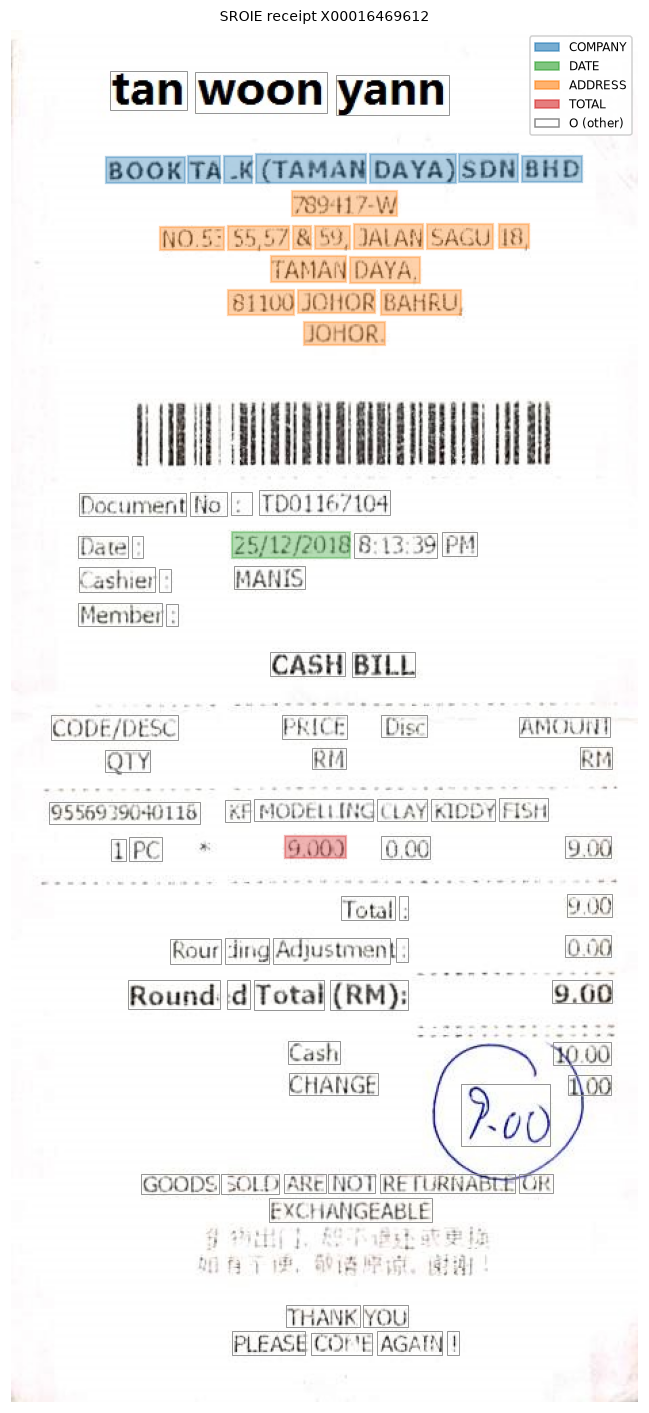

In [24]:
draw_receipt(FIGURE_ROWS[0], images[FIGURE_ROWS[0]["key"]], save_as="receipt_example_1.png")

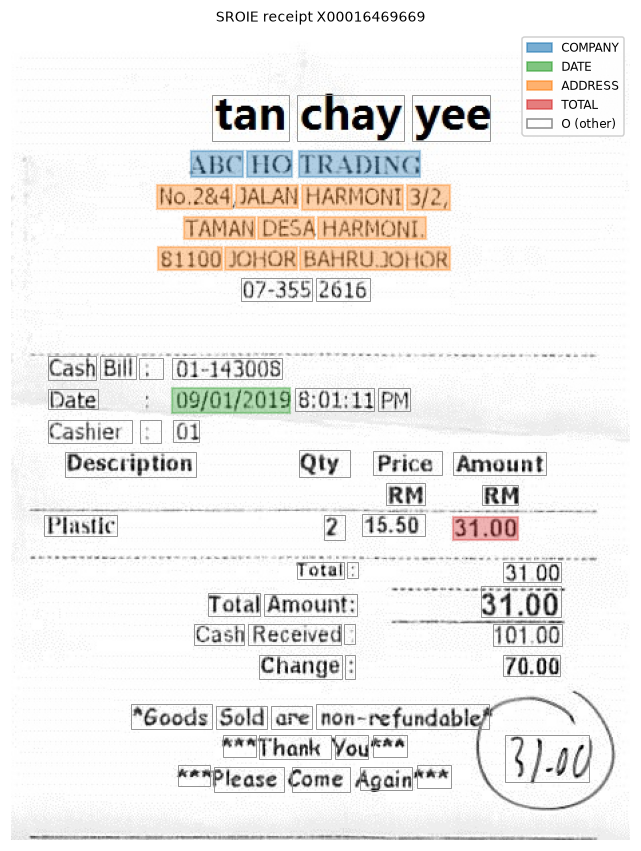

In [25]:
draw_receipt(FIGURE_ROWS[1], images[FIGURE_ROWS[1]["key"]], save_as="receipt_example_2.png")

## 8. Findings

**Data**
- `darentang/sroie` (Parquet copy): **626 train / 347 test** receipts, columns `id, words, bboxes, ner_tags, image_path` (we add `key`).
- `jsdnrs/ICDAR2019-SROIE`: 626 train / 361 test. Every `darentang` receipt matches one by `key`, in the same order. The 14 extra test receipts have no word tags, so **all methods are scored on the 347 shared test receipts**.
- Labels (9): `O, B-COMPANY, I-COMPANY, B-DATE, I-DATE, B-ADDRESS, I-ADDRESS, B-TOTAL, I-TOTAL`.
- Words per receipt: mean **117.8** (train) / **116.5** (test), range 31–246. `O` is **84.7 %** of all words. All four fields are tagged in every receipt (except one train receipt with no address).

**Bounding boxes**
- `darentang` boxes are **already 0–1000** (min 0, max 998/999), integers, and all well-formed. The overlay on the real images lines up word by word, so **LayoutLM (#6) can use `bboxes` as is, with no normalisation**.
- (`jsdnrs` boxes are in pixels and cover whole OCR lines. We don't use them.)

**Length (for #5 / #6)**
- BERT and LayoutLM have **identical vocabularies**, so both models see exactly the same sub-tokens. That keeps the comparison fair.
- Mean **~257 sub-tokens** per receipt (2.2 per word). Only **4 train / 1 test** receipts exceed 512. The words cut off are never field words, so `truncation=True, max_length=512` is safe. Give the cut-off words the label `O` before calling `bio_to_fields`.

**Field spans (for #2 / #3)**
- Every field has **exactly one tagged span** per receipt, so a field is never tagged twice.
- **97.4 %** of DATE spans are a bare date. The rest include `Date:` or a time, a small penalty for the regex baseline.
- **TOTAL is tagged on the first word whose text equals the total amount**, not necessarily the `TOTAL` line. The value is printed more than once in 70 % of receipts, and only **67 %** of TOTAL tags sit on a line with a word like "total"/"amount". (In receipt 1, the tag is on the item price `9.000`.) This makes the layout signal for `total` noisier than expected. It's worth a sentence in the report.
- Some ADDRESS spans also include the company registration number (e.g. `789417-W` in receipt 1).

**Tagged words vs. official answers**
- If a model tagged every word perfectly and we scored it against the official ICDAR answers, it would reach at most **company 80.4 %, date 96.3 %, address 58.2 % (74.4 % ignoring spaces), total 96.3 %**, a macro average of 82.8 %. Mean character similarity is still 0.99. The gap is OCR misreads (`SON`/`SDN`, `26:58`/`26.58`), spacing (`30 ,`), and typos in the official answers.
- ⇒ **Main metric:** exact match against the tagged words (gold from `ner_tags`). It measures what the models control. **Second metric:** exact match against the official answers, reported next to this ceiling. Saved as `results/oracle_ceiling_vs_official.csv`.

**Figures saved to `results/`:** `label_distribution.png`, `words_per_receipt.png`, `subtokens_per_receipt.png`, `receipt_example_1.png`, `receipt_example_2.png`.